# BÀI THỰC HÀNH SỐ 2 - BÀI 4 (TRANG 26): RED WINE QUALITY
**Họ và tên:** Phạm Lê Anh Khoa  
**MSSV:** 6451071035

### Chuẩn bị: Import các thư viện cần thiết và nạp dữ liệu

In [1]:
print("Phạm Lê Anh Khoa - 6451071035")

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

# Đọc dữ liệu Red Wine Quality
df = pd.read_csv('Dataset/winequality-red.csv')
print(f"Kích thước dữ liệu: {df.shape}")
df.info()

Phạm Lê Anh Khoa - 6451071035
Kích thước dữ liệu: (1599, 12)
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


### Câu 3: Khảo sát độ tương đồng giữa các cột với nhau bằng công thức Pearson

Phạm Lê Anh Khoa - 6451071035


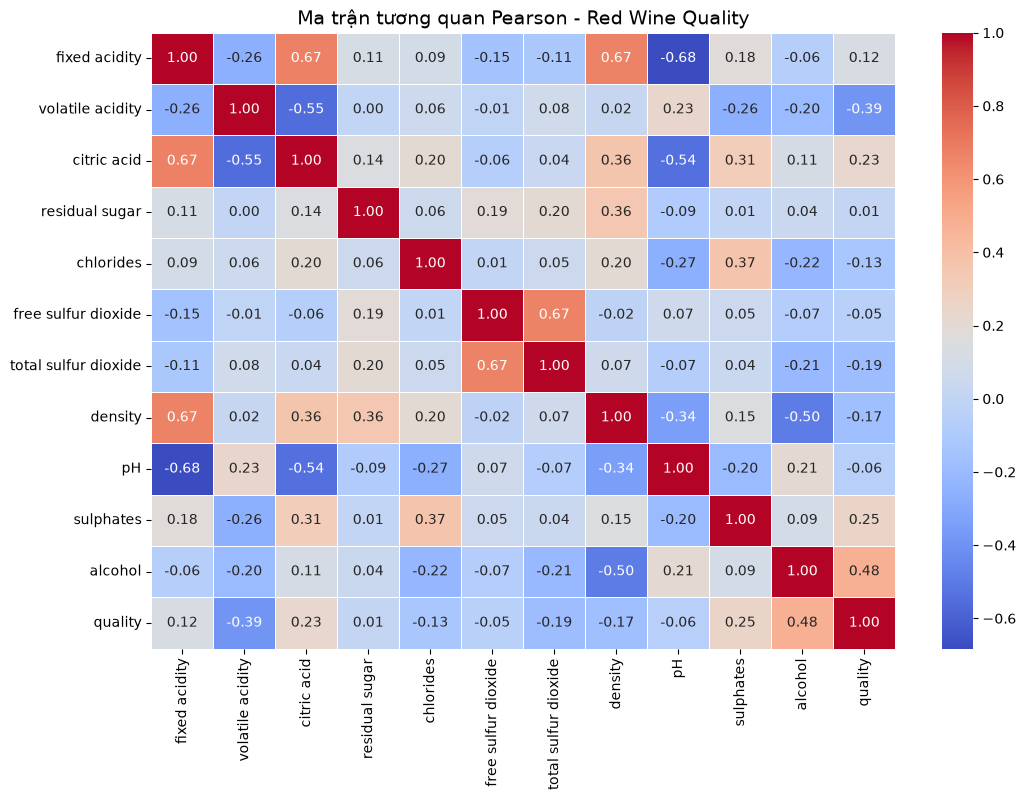

In [2]:
print("Phạm Lê Anh Khoa - 6451071035")

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(method='pearson'), annot=True, fmt=".2f", cmap='coolwarm', linewidths=.5)
plt.title("Ma trận tương quan Pearson - Red Wine Quality", size=14)
plt.show()

**Nhận xét:** Các thuộc tính có hệ số tương quan ở mức vừa và thấp, không có cặp nào tương đồng quá cao dẫn đến hiện tượng đa cộng tuyến nghiêm trọng. Do đó, ta giữ lại tất cả các thuộc tính.

### Câu 4: Tách các cột dữ liệu thành hai phần (`features` và `labels`)

In [3]:
# Tách thuộc tính bình thường và thuộc tính quyết định 'quality'
features = df.drop('quality', axis=1)
labels = df['quality']

### Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector

In [4]:
print("Phạm Lê Anh Khoa - 6451071035")

non_num_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Các thuộc tính không phải dạng số:", list(non_num_cols))

# Vì toàn bộ các đặc trưng đều ở dạng số (float64) nên features_onehot giữ nguyên
features_onehot = features.copy()
features_onehot.head()

Phạm Lê Anh Khoa - 6451071035
Các thuộc tính không phải dạng số: []


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


### Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện (70%) và kiểm thử (30%)

In [5]:
print("Phạm Lê Anh Khoa - 6451071035")

X_train, X_test, y_train, y_test = train_test_split(
    features_onehot, labels, test_size=0.3, random_state=42
)

print(f"Số lượng mẫu huấn luyện: {len(X_train)}")
print(f"Số lượng mẫu kiểm thử: {len(X_test)}")

Phạm Lê Anh Khoa - 6451071035
Số lượng mẫu huấn luyện: 1119
Số lượng mẫu kiểm thử: 480


### Câu 7: Xây dựng cây ID3 dựa trên dữ liệu huấn luyện, kiểm thử bằng ma trận nhầm lẫn và biểu diễn cây

In [6]:
print("Phạm Lê Anh Khoa - 6451071035")

clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)

Phạm Lê Anh Khoa - 6451071035


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [7]:
print("Phạm Lê Anh Khoa - 6451071035")

id3_pred = clf_id3.predict(X_test)
id3_score = metrics.accuracy_score(y_test, id3_pred)
print(f"ID3 Accuracy: {id3_score:.4f} (~{id3_score*100:.2f}%)")
print("\nClassification Report:")
print(metrics.classification_report(y_test, id3_pred, zero_division=0))

Phạm Lê Anh Khoa - 6451071035
ID3 Accuracy: 0.5833 (~58.33%)

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.08      0.12      0.10        17
           5       0.70      0.66      0.68       195
           6       0.60      0.60      0.60       200
           7       0.43      0.46      0.44        61
           8       0.25      0.17      0.20         6

    accuracy                           0.58       480
   macro avg       0.34      0.33      0.34       480
weighted avg       0.59      0.58      0.59       480



Phạm Lê Anh Khoa - 6451071035


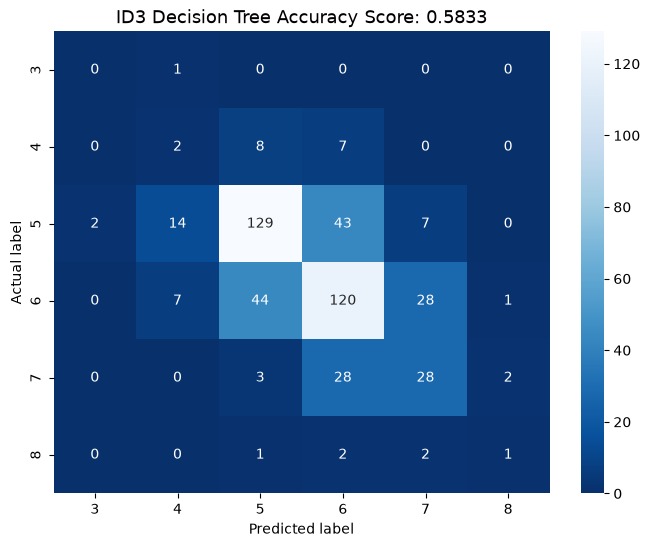

In [8]:
print("Phạm Lê Anh Khoa - 6451071035")

id3_cm = metrics.confusion_matrix(y_test, id3_pred)
unique_labels = sorted(labels.unique())

plt.figure(figsize=(8, 6))
sns.heatmap(id3_cm, annot=True, fmt="d", cmap='Blues_r',
            xticklabels=unique_labels, yticklabels=unique_labels)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'ID3 Decision Tree Accuracy Score: {id3_score:.4f}', size=13)
plt.show()

Phạm Lê Anh Khoa - 6451071035


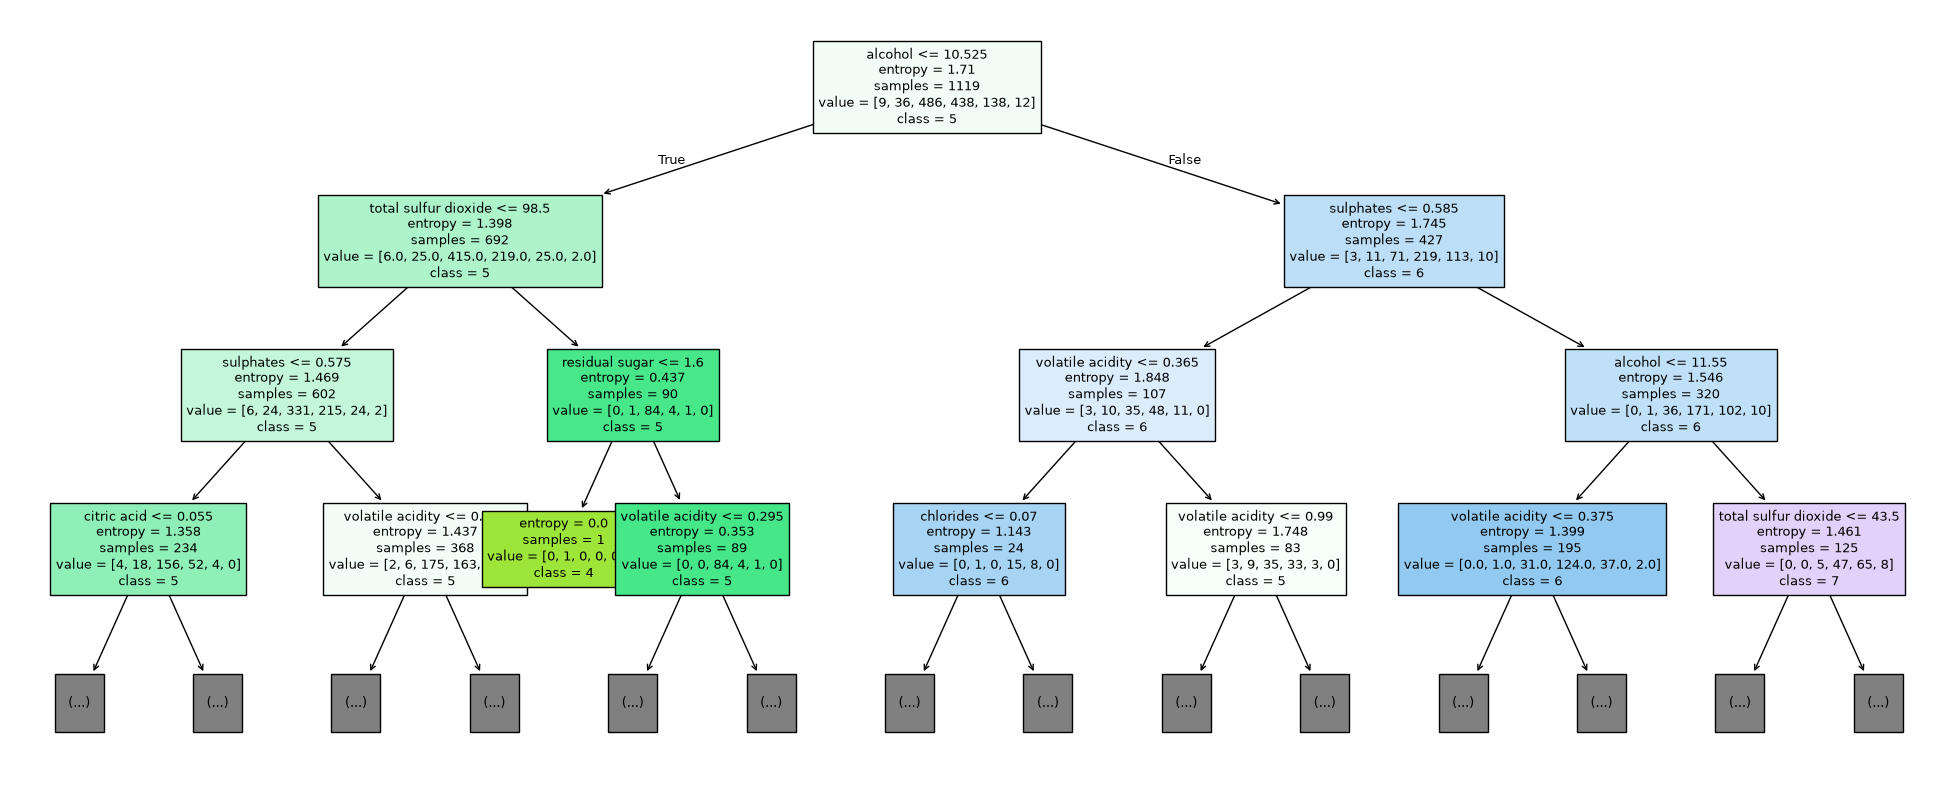

In [9]:
print("Phạm Lê Anh Khoa - 6451071035")

fig, ax = plt.subplots(figsize=(25, 10))
tree.plot_tree(
    clf_id3, 
    max_depth=3, 
    feature_names=features_onehot.columns, 
    class_names=[str(c) for c in unique_labels], 
    filled=True, 
    fontsize=9
)
plt.savefig('wine_decision_tree_id3.png', dpi=100, bbox_inches='tight')
plt.show()

### Câu 8: Lặp lại Câu 7 đối với cây CART (`criterion='gini'`)

In [10]:
print("Phạm Lê Anh Khoa - 6451071035")

clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)

Phạm Lê Anh Khoa - 6451071035


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

In [11]:
print("Phạm Lê Anh Khoa - 6451071035")

cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)
print(f"CART Accuracy: {cart_score:.4f} (~{cart_score*100:.2f}%)")
print("\nClassification Report:")
print(metrics.classification_report(y_test, cart_pred, zero_division=0))

Phạm Lê Anh Khoa - 6451071035
CART Accuracy: 0.5625 (~56.25%)

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.64      0.62      0.63       195
           6       0.57      0.58      0.57       200
           7       0.45      0.49      0.47        61
           8       0.33      0.33      0.33         6

    accuracy                           0.56       480
   macro avg       0.34      0.35      0.35       480
weighted avg       0.56      0.56      0.56       480



Phạm Lê Anh Khoa - 6451071035


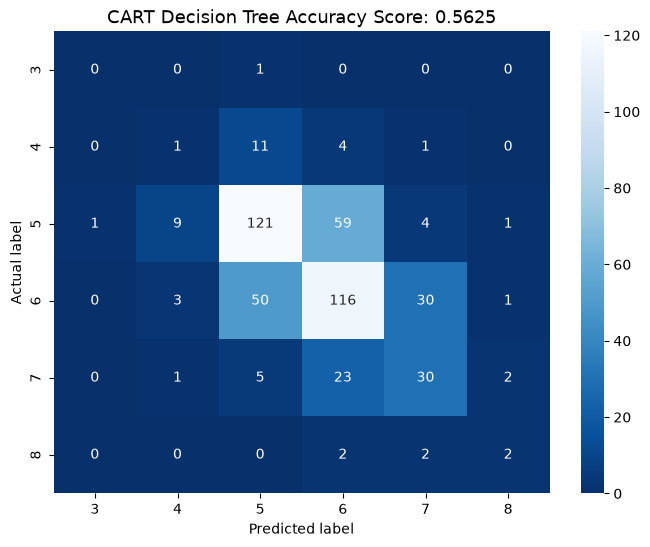

In [12]:
print("Phạm Lê Anh Khoa - 6451071035")

cart_cm = metrics.confusion_matrix(y_test, cart_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt="d", cmap='Blues_r',
            xticklabels=unique_labels, yticklabels=unique_labels)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'CART Decision Tree Accuracy Score: {cart_score:.4f}', size=13)
plt.show()

Phạm Lê Anh Khoa - 6451071035


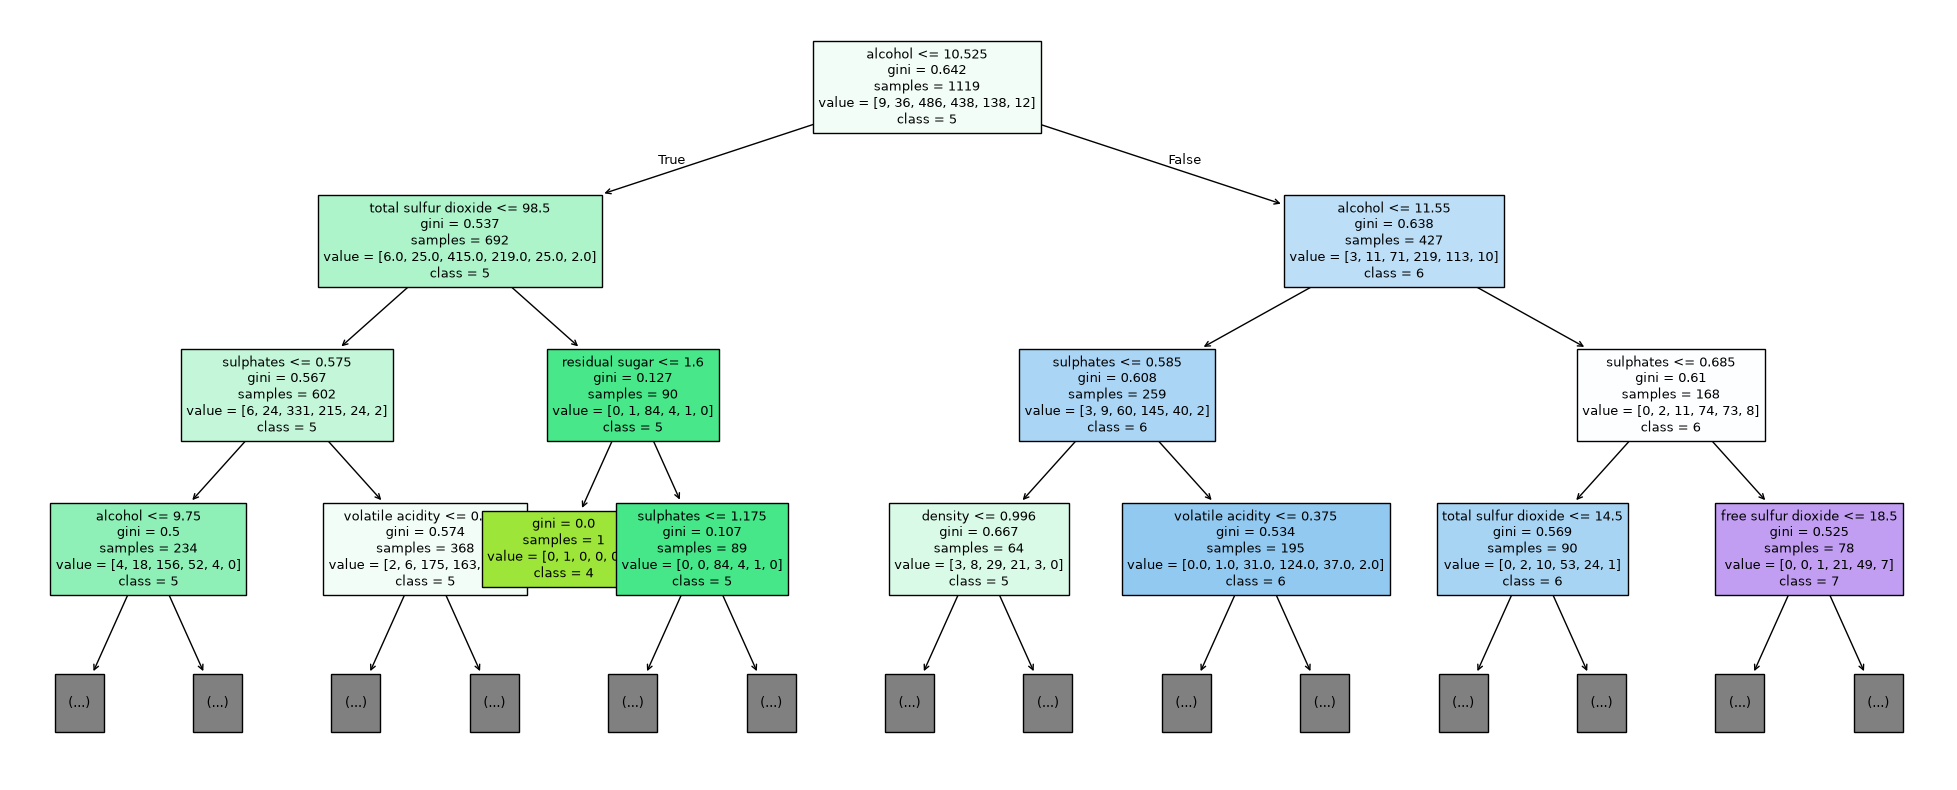

In [13]:
print("Phạm Lê Anh Khoa - 6451071035")

fig, ax = plt.subplots(figsize=(25, 10))
tree.plot_tree(
    clf_cart, 
    max_depth=3, 
    feature_names=features_onehot.columns, 
    class_names=[str(c) for c in unique_labels], 
    filled=True, 
    fontsize=9
)
plt.savefig('wine_decision_tree_cart.png', dpi=100, bbox_inches='tight')
plt.show()

### Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes và kiểm tra kết quả đạt được

In [14]:
print("Phạm Lê Anh Khoa - 6451071035")

gnb = GaussianNB()
gnb.fit(X_train, y_train)
bayes_pred = gnb.predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print(f"Naive Bayes Accuracy: {bayes_score:.4f} (~{bayes_score*100:.2f}%)")
print("\nClassification Report:")
print(metrics.classification_report(y_test, bayes_pred, zero_division=0))

Phạm Lê Anh Khoa - 6451071035
Naive Bayes Accuracy: 0.5417 (~54.17%)

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



Phạm Lê Anh Khoa - 6451071035


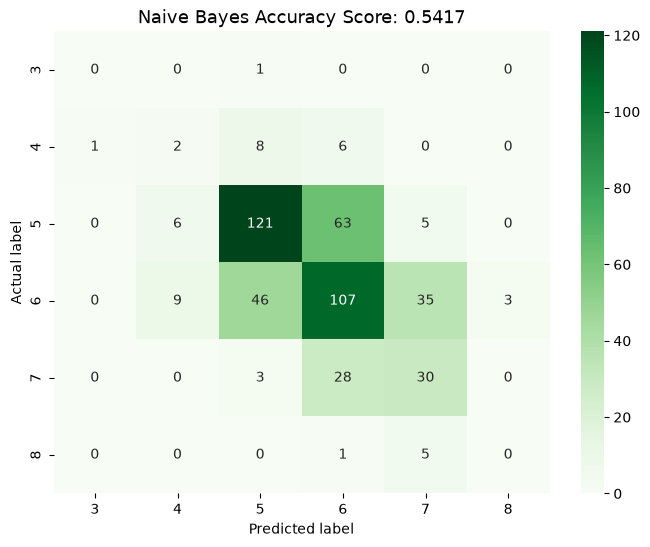

In [15]:
print("Phạm Lê Anh Khoa - 6451071035")

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(bayes_cm, annot=True, fmt="d", cmap='Greens',
            xticklabels=unique_labels, yticklabels=unique_labels)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naive Bayes Accuracy Score: {bayes_score:.4f}', size=13)
plt.show()

### Câu 10: So sánh kết quả của các mô hình trên

In [16]:
print("Phạm Lê Anh Khoa - 6451071035")

print("=== BẢNG SO SÁNH ĐỘ CHÍNH XÁC (ACCURACY) ===")
print(f"1. Cây quyết định ID3 (Entropy) : {id3_score:.4f} (~{id3_score*100:.2f}%)")
print(f"2. Cây quyết định CART (Gini)   : {cart_score:.4f} (~{cart_score*100:.2f}%)")
print(f"3. Naïve Bayes (GaussianNB)     : {bayes_score:.4f} (~{bayes_score*100:.2f}%)")

Phạm Lê Anh Khoa - 6451071035
=== BẢNG SO SÁNH ĐỘ CHÍNH XÁC (ACCURACY) ===
1. Cây quyết định ID3 (Entropy) : 0.5833 (~58.33%)
2. Cây quyết định CART (Gini)   : 0.5625 (~56.25%)
3. Naïve Bayes (GaussianNB)     : 0.5417 (~54.17%)


**Nhận xét và so sánh các mô hình:**
- **Về độ chính xác tổng thể (Accuracy):** Cây quyết định ID3 đạt kết quả cao nhất (~58.33%), kế đến là CART (~56.25%) và thấp nhất là Naïve Bayes (~54.17%).
- **Đặc điểm tập dữ liệu:** Cột nhãn `quality` có 6 giá trị (3, 4, 5, 6, 7, 8) với sự mất cân bằng lớn (mức 5 và 6 chiếm đa số). Do đó, các mô hình phân lớp tốt ở mức 5 và 6 nhưng gặp khó khăn ở các mức điểm hiếm như 3, 4, 8.